# Checkpoint (25 Nov): the first half of the pipeline, working

CSCE 4603 · Option 4 · Object detection from scratch · Mariam Abdelaal, Abdallah Afifi, Youssef Badawy

| Part | Shows | Presenter |
|---|---|---|
| 1. Data | PASCAL VOC filtered to our 5 classes, letterbox resize, augmentation with boxes that follow the image, class counts | Mariam |
| 2. Model | ResNet-style backbone + upsampling neck + CenterNet heads, built from scratch (random init), and the training targets | Abdallah |
| 3. Training | the model can memorise a handful of real images (overfit check), and the loss curve of the full run so far | Abdallah |
| 4. First predictions | `predict.py` on a validation image with the current weights, and the mAP metric that picks the best checkpoint | Youssef |

Run all cells from top to bottom. Data path: `data/VOCdevkit` (change `VOC_ROOT` below if it is elsewhere).

In [1]:
import os, sys, subprocess
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import cv2, numpy as np, torch
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from src import dataset as D
from src.config import load_config
from src.model import build_model, count_parameters, load_model
from src.train_utils import pick_device

VOC_ROOT = "data/VOCdevkit"
# Use VOC 2012 too when it is downloaded; the checkpoint run used VOC 2007 trainval only.
TRAIN_SETS = [(2007, "trainval")]
if (Path(VOC_ROOT) / "VOC2012/ImageSets/Main/trainval.txt").exists():
    TRAIN_SETS.append((2012, "trainval"))
SETS_ARG = "data.train_sets=" + str([list(s) for s in TRAIN_SETS]).replace(" ", "").replace("'", "")
RUN = Path("runs/checkpoint_voc07")         # short full-schedule run of model A for the checkpoint
cfg = load_config("configs/centernet_voc5.yaml")
print("training sets:", TRAIN_SETS)
device = pick_device()
print(f"PyTorch {torch.__version__} | OpenCV {cv2.__version__} | device: {device}")

def run(*args):
    """Run one of our scripts and show its output."""
    out = subprocess.run([sys.executable, *args], capture_output=True, text=True)
    print(out.stdout[-4000:], out.stderr[-2000:] if out.returncode else "")
    out.check_returncode()

training sets: [(2007, 'trainval'), (2012, 'trainval')]
PyTorch 2.15.0 | OpenCV 5.1.0 | device: mps


## 1. Data (Mariam)

PASCAL VOC 2007 + 2012 trainval → keep images with person, car, bicycle, motorbike or bus → 90/10 train/val split (seeded, no shared images). VOC 2007 test stays unseen for the final numbers.

**Class balance.** These are counts before augmentation. "Difficult" objects are dropped from training and ignored by mAP.

| Class | train images | train objects | val images | val objects | test images | test objects |
|---|---:|---:|---:|---:|---:|---:|
| person | 5480 | 11900 | 660 | 1605 | 2097 | 5227 |
| car | 1702 | 2963 | 182 | 367 | 775 | 1541 |
| bicycle | 715 | 955 | 83 | 121 | 250 | 389 |
| motorbike | 679 | 916 | 92 | 150 | 233 | 369 |
| bus | 552 | 748 | 58 | 83 | 183 | 254 |
| **all (images, objects)** | 7320 | 17482 | 1655 | 2326 | 4952 | 7780 |

- train: person is 68.1% of objects; difficult objects: 0; bookkeeping: {'images_only_difficult': 237, 'images_without_5_classes': 7339}
- val: person is 69.0% of objects; difficult objects: 347; bookkeeping: -
- test: person is 67.2% of objects; difficult objects: 1176; bookkeeping: -

saved /Users/abdallahafifi/csce4603-object-detection/docs/figures/class_counts.csv, class_counts.md, class_counts.png
 


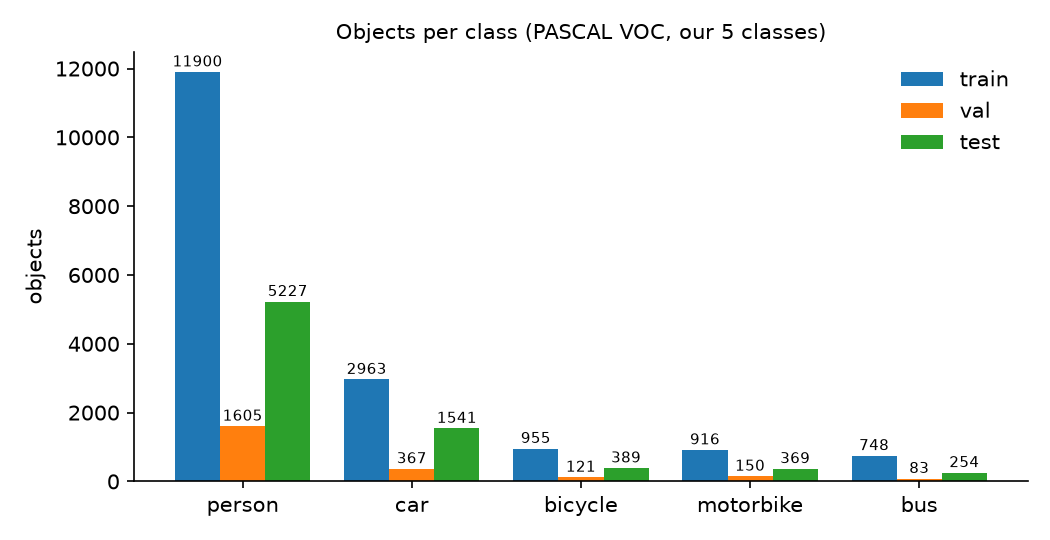

In [2]:
run("scripts/dataset_stats.py", "--set", f"data.voc_root={VOC_ROOT}", SETS_ARG)
display(Image("docs/figures/class_counts.png"))

**Resize and augmentation.**
- Every image is letterboxed to 384×384: the aspect ratio is kept and the borders are padded with the mean colour.
- Training images are also randomly cropped, flipped and colour-jittered, and the boxes are transformed with the image.
- The first column of the figure is the plain letterboxed image; the other columns are random augmentations of it.

saved /Users/abdallahafifi/csce4603-object-detection/docs/figures/augmented_samples.png
 


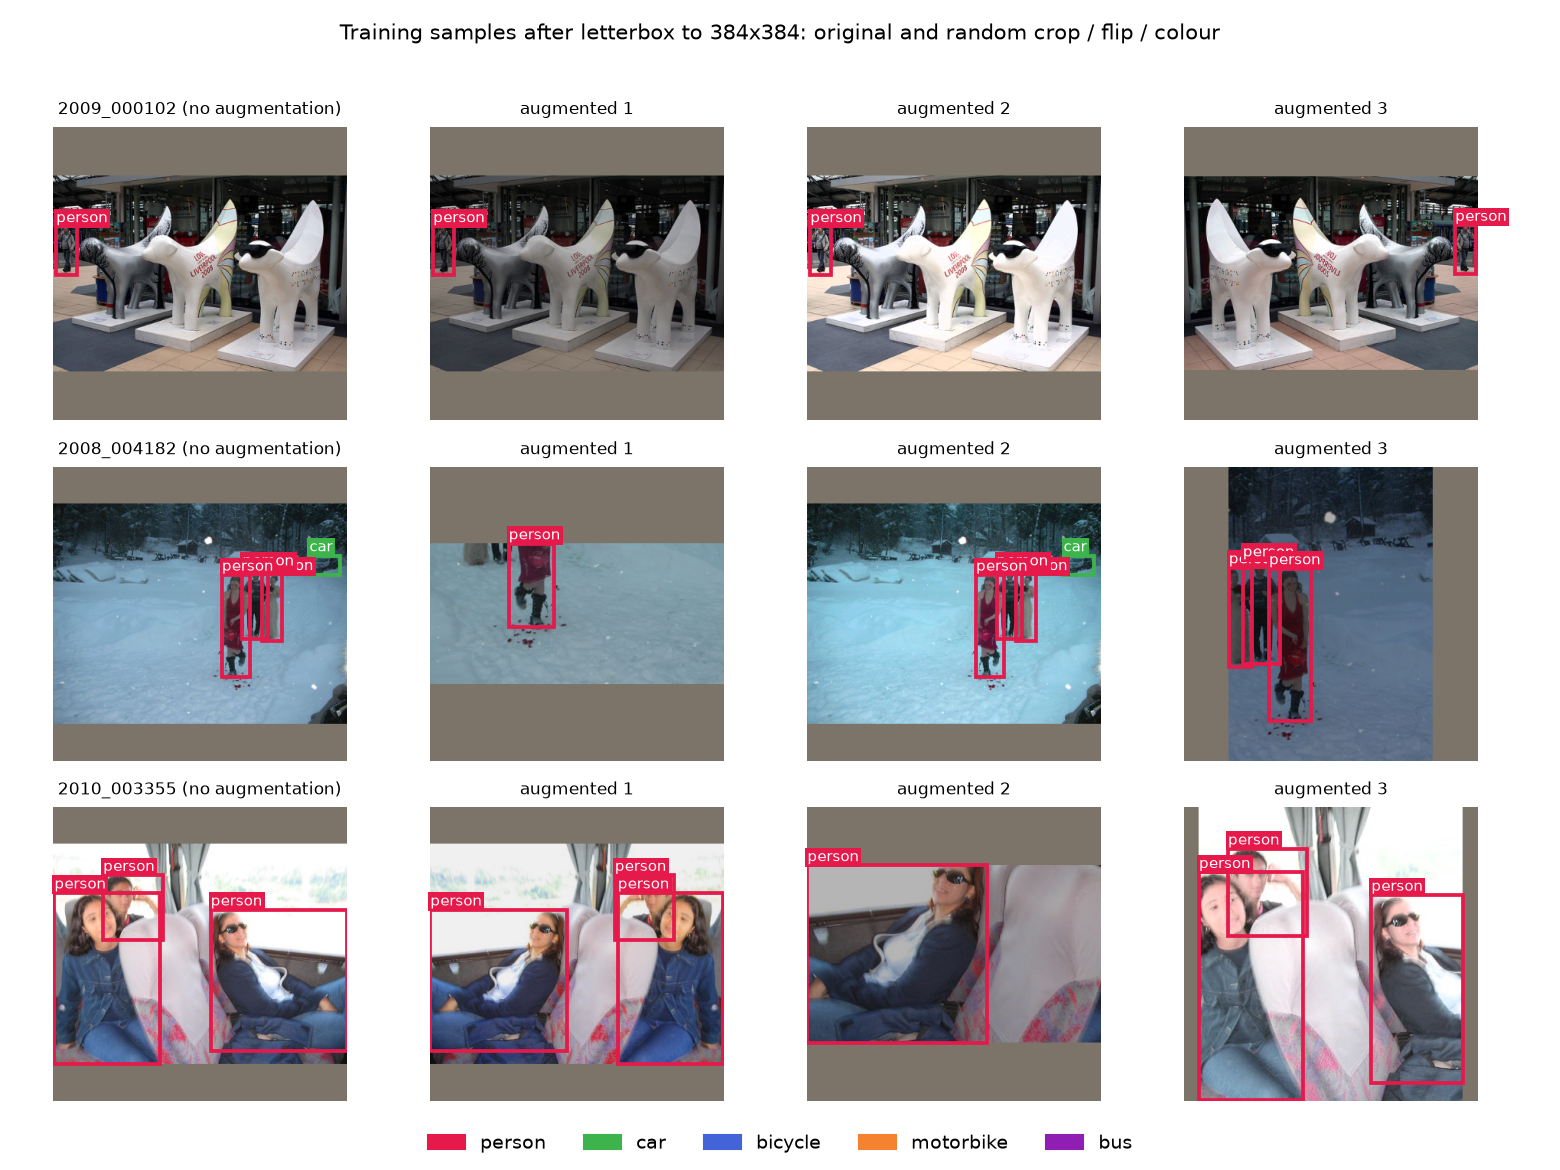

In [3]:
run("scripts/show_samples.py", "--set", f"data.voc_root={VOC_ROOT}", SETS_ARG, "--images", "3", "--augs", "3")
display(Image("docs/figures/augmented_samples.png"))

In [4]:
train_ds = D.VOC5Dataset(VOC_ROOT, sets=TRAIN_SETS, split="train", augment=True)
val_ds = D.VOC5Dataset(VOC_ROOT, sets=TRAIN_SETS, split="val")
image, target = train_ds[0]
print(train_ds, "\n", val_ds)
print("image:", tuple(image.shape), image.dtype, "| boxes:", tuple(target["boxes"].shape), "| labels:", target["labels"].tolist())
print("bookkeeping:", dict(train_ds.info))

VOC5Dataset(split=train, sets=[(2007, 'trainval'), (2012, 'trainval')], images=7320, augment=True) 
 VOC5Dataset(split=val, sets=[(2007, 'trainval'), (2012, 'trainval')], images=1655, augment=False)
image: (3, 384, 384) torch.float32 | boxes: (3, 4) | labels: [0, 0, 0]
bookkeeping: {'images_without_5_classes': 7339, 'images_only_difficult': 237, 'images': 7320}


## 2. Model (Abdallah)

- **Backbone:** a ResNet-18-style network (3-conv stem, 4 stages of residual blocks) starting from random weights, with no pretrained model.
- **Neck:** an FPN-style upsampling path that brings the features back to 1/4 resolution (96×96), so small objects survive.
- **Heads:** three small heads predict a heatmap of object centres per class, the box width/height, and a sub-cell offset.

In [5]:
run("scripts/model_summary.py", "--config", "configs/centernet_voc5.yaml")

CenterNet for 5 classes ['person', 'car', 'bicycle', 'motorbike', 'bus'], input 384x384
part              params
backbone          11.20M
neck               0.57M
heatmap            0.07M
wh                 0.07M
offset             0.07M
total             11.98M
conv MACs per image: 9.49 G
backbone features: s4 (64, 96, 96), s8 (128, 48, 48), s16 (256, 24, 24), s32 (512, 12, 12)
head outputs:      heatmap (5, 96, 96), wh (2, 96, 96), offset (2, 96, 96)
forward + decode on mps: 7.0 ms/image (142.0 FPS, batch 1)
 


**What the network learns to predict.** For each true box, the target is a Gaussian "bump" at the box centre on its class channel. The radius comes from the box size, so a centre slightly off still gives IoU ≥ 0.7. Training pushes the heatmap toward these bumps with focal loss, plus L1 loss on box size and offset at the centres.

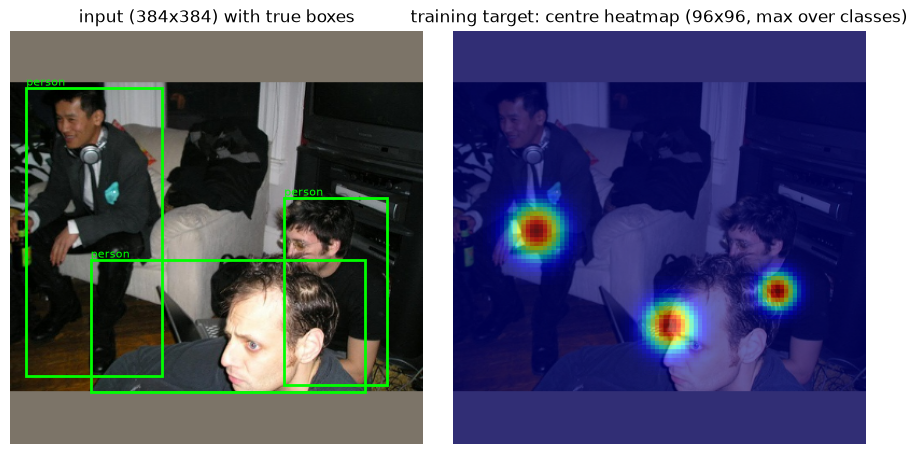

In [6]:
model = build_model(cfg)
encoder = model.target_encoder()
# a validation image with a clearly visible object (box covering >= 15% of the image)
big = next(i for i, r in enumerate(val_ds.records) if len(r['boxes']) >= 2 and
           ((r['boxes'][:, 2] - r['boxes'][:, 0]) * (r['boxes'][:, 3] - r['boxes'][:, 1])).max() > 0.15 * 500 * 375)
image, target = val_ds[big]
enc = encoder(target["boxes"].numpy(), target["labels"].numpy(), (384, 384))
heat = cv2.resize(enc["heatmap"].max(0), (384, 384), interpolation=cv2.INTER_NEAREST)

rgb = D.denormalize(image)[..., ::-1]
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(rgb)
for (x1, y1, x2, y2), lab in zip(target["boxes"].tolist(), target["labels"].tolist()):
    axes[0].add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="lime", lw=2))
    axes[0].text(x1, y1 - 2, D.CLASSES[lab], color="lime", fontsize=8)
axes[0].set_title("input (384x384) with true boxes")
axes[1].imshow(rgb); axes[1].imshow(heat, alpha=0.6, cmap="jet")
axes[1].set_title("training target: centre heatmap (96x96, max over classes)")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Training (Abdallah)

**Overfit check.** Before spending hours on GPU we check that the whole loop (data → targets → loss → decode) is consistent: the model must memorise 8 real training images in a few hundred steps. Green boxes are the ground truth, red are the predictions.

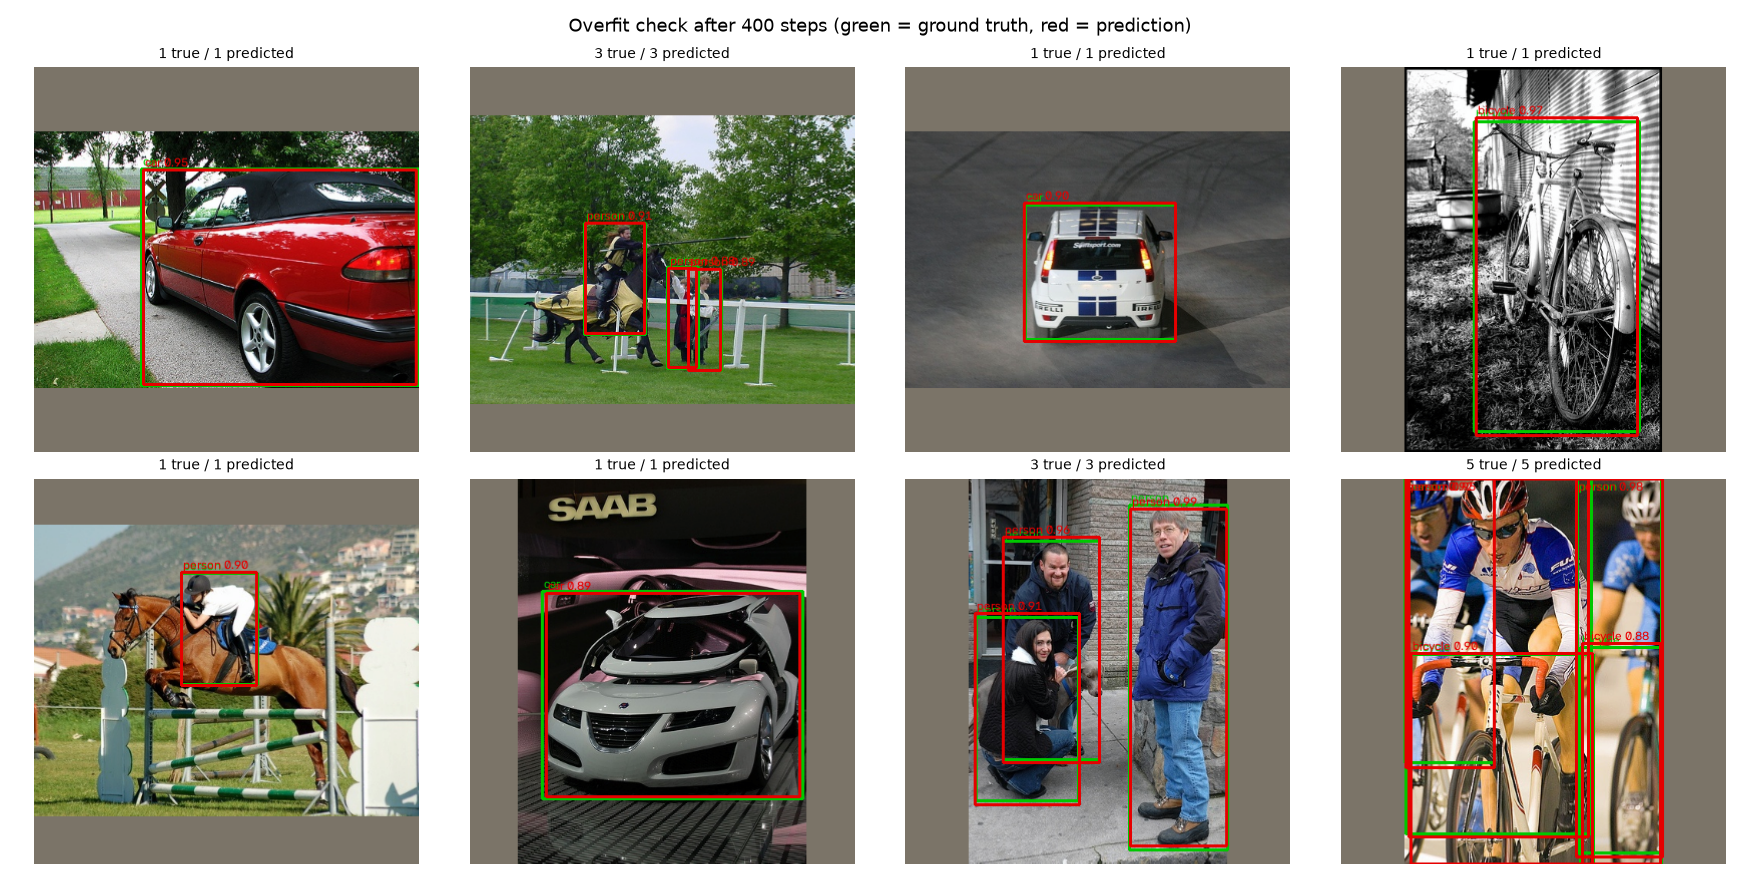

In [7]:
RERUN_OVERFIT = False    # True re-trains it live (~2 min on a laptop GPU); False shows the saved result
if RERUN_OVERFIT or not Path("docs/figures/overfit_check.png").exists():
    run("scripts/overfit_check.py", "--config", "configs/centernet_voc5.yaml", "--set", f"data.voc_root={VOC_ROOT}", SETS_ARG, "--steps", "400")
display(Image("docs/figures/overfit_check.png"))

**Training run for the checkpoint.** This is model A with the full recipe (AdamW, warm-up + cosine schedule, EMA weights, val mAP every 5 epochs), on VOC 2007 trainval only and a short 40-epoch schedule, so it finishes in the time we had. The real run A uses VOC 2007 + 2012 for 120 epochs.

```
python scripts/train.py --config configs/centernet_voc5.yaml --out runs/checkpoint_voc07 \
    --set "data.train_sets=[[2007,trainval]]" train.epochs=40 train.warmup_epochs=2
```

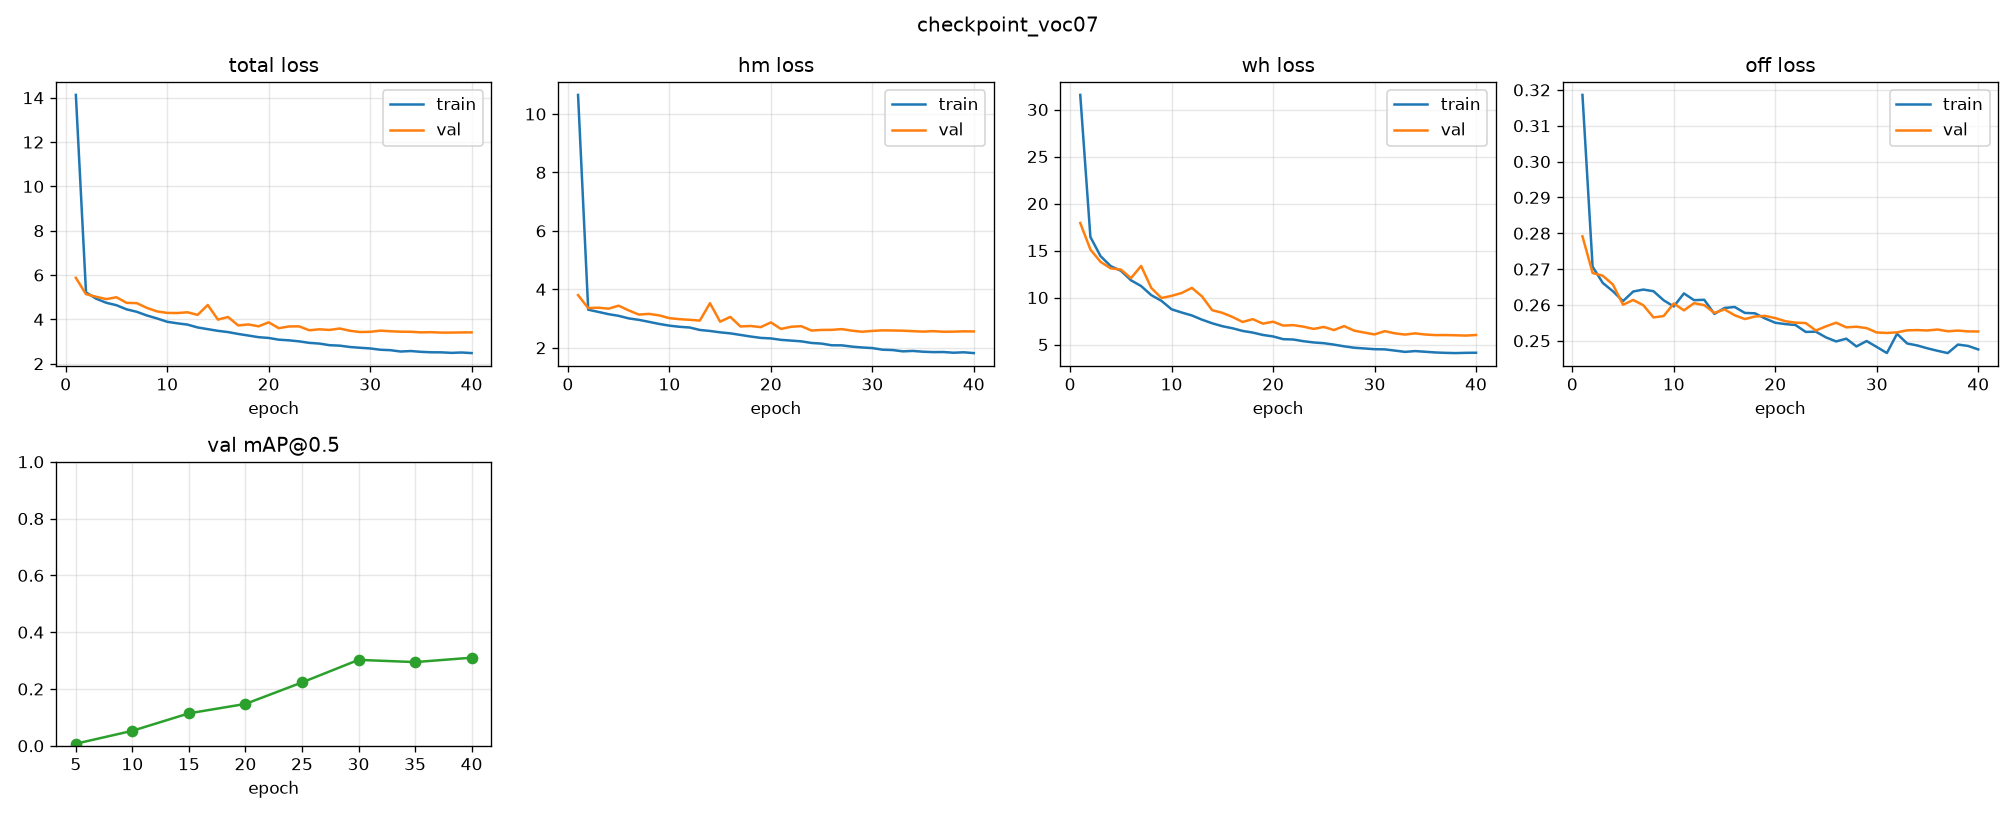

       epoch            lr   train_total     val_total       val_mAP  epoch_minutes
          33      9.09e-05         2.548         3.443             -        0.4851
          34     6.992e-05          2.57         3.439             -        0.4891
          35     5.191e-05         2.535         3.412        0.2947        0.5089
          36       3.7e-05         2.514         3.422             -        0.4901
          37     2.528e-05         2.512         3.402             -        0.4902
          38     1.684e-05         2.488         3.403             -        0.4871
          39     1.174e-05         2.505          3.41             -        0.4885
          40         1e-05         2.478         3.412        0.3103        0.5188


In [8]:
import csv
display(Image(str(RUN / "loss_curve.png")))
rows = list(csv.DictReader(open(RUN / "history.csv")))
cols = ["epoch", "lr", "train_total", "val_total", "val_mAP", "epoch_minutes"]
print("  ".join(f"{c:>12}" for c in cols))
for r in rows[-8:]:
    print("  ".join(f"{float(r[c]):>12.4g}" if r.get(c) not in (None, "") else f"{'-':>12}" for c in cols))

## 4. First predictions (Youssef)

`predict.py` loads the current weights, prepares the image exactly like training (`preprocess`), decodes the heatmap peaks into boxes, maps them back to the original image, and draws them. These are the checkpoint run's final weights (epoch 40, VOC 2007 only), so expect misses and loose boxes.

weights: runs/checkpoint_voc07/best.pt | epoch 40 | score threshold 0.22


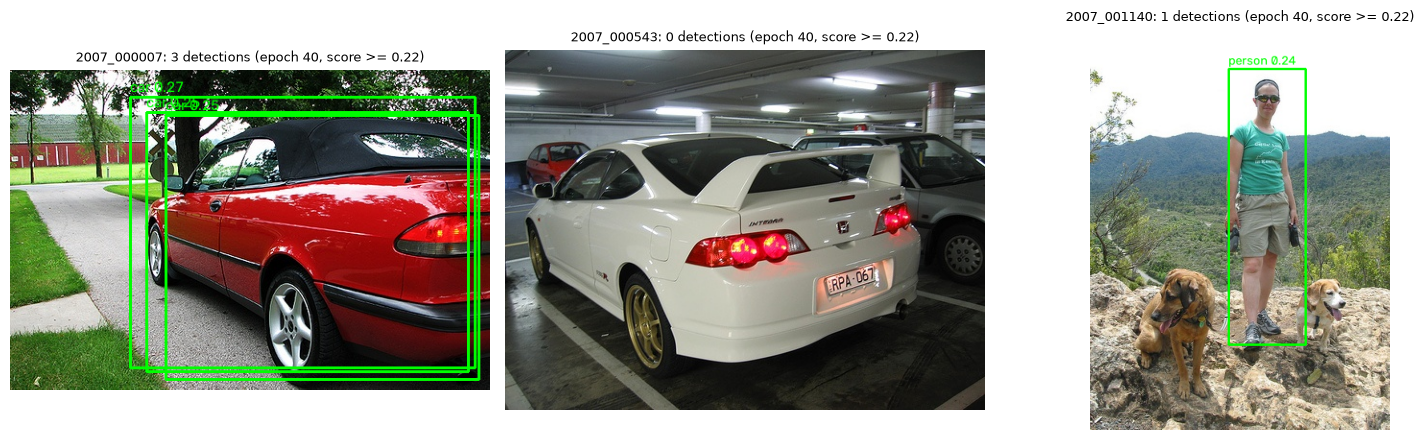

In [9]:
from scripts.predict import draw, predict_image
weights = RUN / ("best.pt" if (RUN / "best.pt").exists() else "last.pt")
det_model, det_cfg = load_model(weights, device=device)
epoch = torch.load(weights, map_location="cpu", weights_only=False)["epoch"]
THRESH = 0.22   # the best-F1 threshold chosen on the validation split
print("weights:", weights, "| epoch", epoch, "| score threshold", THRESH)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
with_objects = [i for i, r in enumerate(val_ds.records) if len(r['labels'])][:40]
for ax, idx in zip(axes, with_objects[::13][:3]):
    bgr, *_ = val_ds.load_raw(idx)
    boxes, scores, labels = predict_image(det_model, bgr, det_cfg["input_size"], thresh=THRESH)
    ax.imshow(draw(bgr, boxes, scores, labels, det_cfg["classes"])[..., ::-1])
    ax.set_title(f"{val_ds.records[idx]['id']}: {len(boxes)} detections (epoch {epoch}, score >= {THRESH})", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

**Test-set numbers for the checkpoint run** (`scripts/evaluate.py`):
- **Data:** all 4,952 VOC 2007 test images, never used for training or model selection.
- **Threshold:** the score threshold for precision/recall is the best-F1 threshold on the validation split.
- **Confusion matrix:** rows are true classes, columns predicted classes. "missed" means an object nobody detected; "false pos." means a detection with no object behind it.

| Run | epoch | mAP@0.5 | mAP (VOC07 11-pt) | AP person | AP car | AP bicycle | AP motorbike | AP bus | threshold | precision | recall | F1 | error rate | FPS |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| checkpoint_voc07 | 40 | 0.266 | 0.291 | 0.377 | 0.388 | 0.198 | 0.265 | 0.102 | 0.22 | 0.410 | 0.418 | 0.414 | 0.739 | 141 |

Test set: 4952 images. Threshold = best F1 on the validation split (not tuned on test). Error rate = (FP + FN) / (TP + FP + FN). FPS = batch 1, model + decode, on mps.


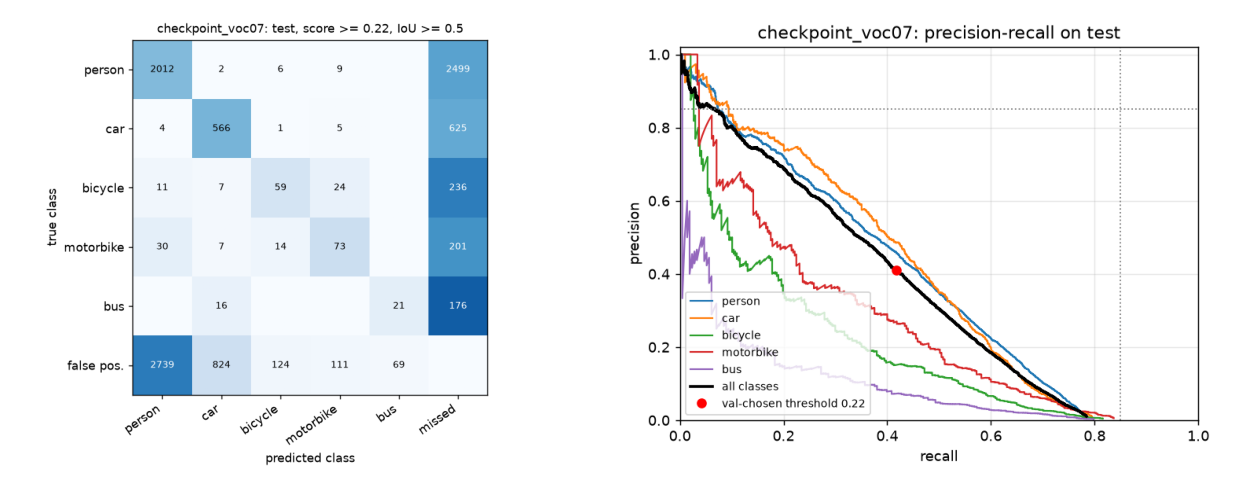

In [10]:
from IPython.display import Markdown
EVAL = Path("docs/results/checkpoint_voc07/test_eval")
display(Markdown((EVAL / "summary.md").read_text()))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, ["confusion_matrix.png", "pr_curve.png"]):
    ax.imshow(plt.imread(EVAL / "checkpoint_voc07" / name)); ax.axis("off")
plt.tight_layout(); plt.show()

## What is next (second half)

- **Training:** finish run A, plus the comparison runs B (no augmentation) and C (our own grid head, idea from YOLO v1).
- **Prediction:** `predict.py` on our own campus videos, with box overlay and FPS.
- **Evaluation:** mAP@0.5, precision/recall, confusion matrix and per-class AP on VOC 2007 test and on our labelled video frames.
- **Report:** failure cases.